In [71]:
import pyranges as pr
import os
import gzip
import pandas as pd
import numpy as np
from scipy.sparse import dok_matrix

from hicexplorer import hicConvertFormat
from hicexplorer import hicSumMatrices

import hicmatrix.HiCMatrix as hm
from hicexplorer import utilities
import scipy.sparse as sp

import tempfile
import copy

import pyBigWig
import gzip
from sklearn.preprocessing import MinMaxScaler
import random

import networkx as nx

import community as community_louvain

from icecream import ic

from collections import OrderedDict

import matplotlib.pyplot as plt
%matplotlib inline
import umap.umap_ as umap
reducer = umap.UMAP()

import sklearn.decomposition as skd

import traceback

In [72]:
ROOT_PATH = '/Users/joachimwolff/data/epigenetic_graph_analyzer/'
path_interactions_E12_5_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.txt.gz"
# path_interactions_E12_5_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.txt.gz"

path_interactions_E14_5_rep1 = ROOT_PATH + "phic/GSM6505216_Pinna_E14.5_CapHiC_Chicago_output_washU_text.txt.gz"
# path_interactions_E14_5_rep2 = ROOT_PATH + "phic/GSM6505217_Pinna_E14.5_CapHiC_3rdBioRep_cd_washU_text.txt.gz"

path_output_bedpe_E12_5_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.bedpe"
path_output_bedpe_E12_5_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.bedpe"

path_output_bedpe_E14_5_rep1 = ROOT_PATH + "phic/GSM6505216_Pinna_E14.5_CapHiC_Chicago_output_washU_text.bedpe"
path_output_bedpe_E14_5_rep2 = ROOT_PATH + "phic/GSM6505217_Pinna_E14.5_CapHiC_3rdBioRep_cd_washU_text.bedpe"

path_output_cool_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.cool"
path_output_cool_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.cool"

path_output_cool_merged = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_merged.cool"


path_mm10_chromosome_size = ROOT_PATH + "mm10.chrom.sizes.sort"
path_promoter = ROOT_PATH + "mm10_promoter.bed"


# histones
path_histones_H3K3me2_E12_5_rep1 = ROOT_PATH + "histones/GSM6505186_H3K4me2_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K3me2_E12_5_rep2 = ROOT_PATH + "histones/GSM6505187_H3K4me2_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K3me2_E14_5_rep1 = ROOT_PATH + "histones/GSM6505192_H3K4me2_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K3me2_E14_5_rep2 = ROOT_PATH + "histones/GSM6505193_H3K4me2_Pinna_E14.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27me3_E12_5_rep1  = ROOT_PATH + "histones/GSM6505188_H3K27me3_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27me3_E12_5_rep2  = ROOT_PATH + "histones/GSM6505189_H3K27me3_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27me3_E14_5_rep1  = ROOT_PATH + "histones/GSM6505194_H3K27me3_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27me3_E14_5_rep2  = ROOT_PATH + "histones/GSM6505195_H3K27me3_Pinna_E14.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27ac_E12_5_rep1  = ROOT_PATH + "histones/GSM6505184_H3K27ac_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27ac_E12_5_rep2  = ROOT_PATH + "histones/GSM6505185_H3K27ac_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27ac_E14_5_rep1  = ROOT_PATH + "histones/GSM6505190_H3K27ac_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27ac_E14_5_rep2  = ROOT_PATH + "histones/GSM6505191_H3K27ac_Pinna_E14.5_WT_rep2.scaled_0100.bw"


# RNA
path_RNA_E12_5_rep1 = ROOT_PATH + "RNA/GSM6505221_RNAseq_E12.5-Pinna_TruSeq_1_cpm_100.bw"
path_RNA_E12_5_rep2 = ROOT_PATH + "RNA/GSM6505222_RNAseq_E12.5-Pinna_TruSeq_2_cpm_100.bw"
path_RNA_E12_5_rep3 = ROOT_PATH + "RNA/GSM6505223_RNAseq_E12.5-Pinna_TruSeq_3_cpm_100.bw"

path_RNA_E14_5_rep1 = ROOT_PATH + "RNA/GSM6505224_RNAseq_E14.5-Pinna_TruSeq_1_cpm_100.bw"
path_RNA_E14_5_rep2 = ROOT_PATH + "RNA/GSM6505225_RNAseq_E14.5-Pinna_TruSeq_2_cpm_100.bw"
path_RNA_E14_5_rep3 = ROOT_PATH + "RNA/GSM6505226_RNAseq_E14.5-Pinna_TruSeq_3_cpm_100.bw"

# ATAC
path_ATAC_E12_5_rep1 = ROOT_PATH + "ATAC/GSM6505176_ATAC_WT_E12.5_Pinna_SK_1.scaled_0100.bw"
path_ATAC_E12_5_rep2 = ROOT_PATH + "ATAC/GSM6505177_ATAC_WT_E12.5_Pinna_SK_2.scaled_0100.bw"
path_ATAC_E12_5_rep3 = ROOT_PATH + "ATAC/GSM6505178_ATAC_WT_E12.5_Pinna_SK_3.scaled_0100.bw"

path_ATAC_E14_5_rep1 = ROOT_PATH + "ATAC/GSM6505179_ATAC_E14.5_WT_Pinna_SK_1.scaled_0100.bw"
path_ATAC_E14_5_rep2 = ROOT_PATH + "ATAC/GSM6505180_ATAC_E14.5_WT_Pinna_SK_2.scaled_0100.bw"
path_ATAC_E14_5_rep3 = ROOT_PATH + "ATAC/GSM6505181_ATAC_E14.5_WT_Pinna_SK_3.scaled_0100.bw"



In [4]:
def washU_to_bedpe(path_input, path_output):
    pd_interactions = pd.read_table(path_input, header=None, sep='\t|,', compression='gzip')
    pd_interactions['name'] = [str(x) for x in range(len(pd_interactions))]
    pd_interactions.to_csv(path_output, index=False, header=False, sep='\t', mode='a')

In [45]:
washU_to_bedpe(path_interactions_E12_5_rep1, path_output_bedpe_E12_5_rep1)
# washU_to_bedpe(path_interactions_E12_5_rep2, path_output_bedpe_E12_5_rep2)
washU_to_bedpe(path_interactions_E14_5_rep1, path_output_bedpe_E14_5_rep1)
# washU_to_bedpe(path_interactions_E14_5_rep2, path_output_bedpe_E14_5_rep2)

In [73]:

def importInteractionsFromWashU(list_of_washU_files, chromosome_size_file, resolution, allow_inter_chr_interactions=False):
    
    hic_matrix_list = []
    matrix_merged_csr = None
   
    for i, path_interactions in enumerate(list_of_washU_files):
        pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression='gzip')
        
        chrom_sizes = OrderedDict()
        size_genome = 0
        with open(chromosome_size_file, 'r') as file:
            file_ = True
            while file_:
                file_ = file.readline().strip()
                if file_ != '':
                    line_split = file_.split('\t')
                    chrom_sizes[line_split[0]] = int(line_split[1])
                    size_genome += int(line_split[1])
        # chrom_sizes = list(chrom_sizes.items())

        cut_intervals = []
        if isinstance(resolution, int):
            for chromosome in chrom_sizes:
                for interval in range(0, chromosome[1], resolution):
                    cut_intervals.append(tuple([chromosome[0], interval,
                                                min(chromosome[1], interval + resolution), 1.0]))
        else:
            restriction_cut_sites = pd.read_table(resolution, sep='\t')
            # restriction_cut_sites.columns = ['Chromosome', 'Start', 'End', '.', 'x', 'Strand']
            for row in restriction_cut_sites.iterrows():
                if row[1]['Chromosome'] in chrom_sizes:
                    cut_intervals.append(tuple([str(row[1]['Chromosome']), int(row[1]['Start']), int(row[1]['End']), 1.0]))
        hic_matrix_csr = dok_matrix((len(cut_intervals), len(cut_intervals)))

        hic_matrix = hm.hiCMatrix()
        hic_matrix.setMatrix(hic_matrix_csr, cut_intervals)
        for row in pd_interactions.iterrows():
            
            chromosome_1 = str(row[1][0])
            start_1 = int(row[1][1]) + 1
            end_1 = int(row[1][2]) - 1

            chromosome_2 = str(row[1][3])
            start_2 = int(row[1][4]) + 1
            end_2 = int(row[1][5]) - 1

            value = float(row[1][6])

            if not allow_inter_chr_interactions:
                if chromosome_1 != chromosome_2:
                    continue
            
            try:
                bin_id_1 = hic_matrix.getRegionBinRange(chromosome_1, start_1, end_1)
                bin_id_2 = hic_matrix.getRegionBinRange(chromosome_2, start_2, end_2)
                hic_matrix.matrix[bin_id_1, bin_id_2] = value

            except Exception as exp:
                print(traceback.print_exc())
                ic(chromosome_1, start_1, end_1)
                ic(chromosome_2, start_2, end_2)
                break
                # continue
            
            
        hic_matrix.matrix = hic_matrix.matrix.tocsr()
        hic_matrix_list.append(hic_matrix)
        if matrix_merged_csr is None:
            matrix_merged_csr = hic_matrix_list[0].matrix.tocsr()
        else:
            matrix_merged_csr += hic_matrix_list[i].matrix.tocsr()
        
    hic_matrix_list.append(matrix_merged_csr)
    return hic_matrix_list

In [ ]:
# chr6	52164817	52164877	Hoxa2_1

In [74]:
interaction_matrices_sample_Pinna_12_5 = importInteractionsFromWashU([path_interactions_E12_5_rep1], path_mm10_chromosome_size, resolution=os.path.join(ROOT_PATH, 'hicup_digest/mm10_hindIII.txt'))
interaction_matrices_sample_Pinna_14_5 = importInteractionsFromWashU([path_interactions_E14_5_rep1], path_mm10_chromosome_size, resolution=os.path.join(ROOT_PATH, 'hicup_digest/mm10_hindIII.txt'))


In [76]:
interaction_matrices_sample_Pinna_14_5[0].matrix[617308, :]

<1x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 23 stored elements in Compressed Sparse Row format>

In [77]:
def createSampleInteractionMatrix(path_promoter, chic_matrix):
    pyrange_promoter = pr.read_bed(path_promoter)

    matrix_list = []
    bait_list = []
    for index, row in pyrange_promoter.as_df().iterrows():
        bait_location = row[['Chromosome', 'Start', 'End']]
        
        view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1], bait_location[1])
        if view_point_start is None:
            
            view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1]+1, bait_location[1]+1)
            
            if view_point_start is None:
                print(traceback.print_exc())
                ic(bait_location, row)
                break
        matrix_list.append(chic_matrix[0].matrix[view_point_start[0], :])
        bait_list.append(row[['Name']])

    # Assuming you have a list of CSR matrices: matrix_list
    sample_matrix = sp.vstack(matrix_list)
    return sample_matrix, bait_list

In [78]:
sample_matrix_Pinna_E12_5, bait_list_Pinna_E12_5 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_Pinna_12_5)
sample_matrix_Pinna_E14_5, bait_list_Pinna_E14_5 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_Pinna_14_5)

ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/joachimwolff/opt/miniconda3_x86/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/joachimwolff/opt/miniconda3_x86/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/joachimwolff/opt/miniconda3_x86/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
E

In [79]:
bait_list_Pinna_E14_5_df = pd.DataFrame(bait_list_Pinna_E14_5, columns=['Name'])
bait_list_Pinna_E14_5_df[bait_list_Pinna_E14_5_df["Name"] == "Hoxa2_1"]


,Name
8767,Hoxa2_1


In [97]:
promoters = pr.read_bed(path_promoter)

In [103]:
promoters.df[promoters.df['Name'] == 'Tax1bp1_2']

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd
8147,chr6,52713984,52714044,Tax1bp1_2,900,+,52714033,52714044


In [84]:
def createGraphAndFindCommunities(sample_matrix, bait_list, path_output_graphml):
    G = nx.Graph()
    number_of_samples = sample_matrix.shape[0]
    bait_ids, OE_ids = sample_matrix.nonzero()
    for i, (bait, OE) in enumerate(zip(bait_ids, OE_ids)):
        if bait == 8767:
            ic(bait, OE, sample_matrix.data[i])
        if (bait != OE):
            G.add_weighted_edges_from([(bait, OE+number_of_samples, sample_matrix.data[i])])
            G.nodes[OE + number_of_samples]['colorType'] = "orange"


    for bait in bait_ids:
        G.nodes[bait]['name'] = bait_list[bait][0]
        G.nodes[bait]['colorType'] = "green"

    partition = community_louvain.best_partition(G)
    partition = nx.community.louvain_communities(G, seed=42)

    for partition_id, partition in enumerate(partition):
        for node in partition:
            G.nodes[node]['partition'] = partition_id
            G.nodes[node]['partition_color'] = partition_id



    nx.write_graphml(G, path_output_graphml)

    return G, partition

In [82]:
partition = nx.community.louvain_communities(G_Pinna_E12_5, seed=42)

In [83]:
partition

[{1, 26258, 52468},
 {2, 26130, 26147, 26149, 26150, 26154},
 {4, 25784},
 {6, 26463, 26464, 26553, 26574},
 {20, 27647, 28611},
 {21, 27850},
 {23, 28143, 28173, 28197, 28327, 28384},
 {25, 28654},
 {26, 29340, 29841},
 {28, 827, 30058, 30073},
 {31,
  32,
  830,
  29974,
  30067,
  30068,
  30071,
  30074,
  30076,
  30077,
  30079,
  30080,
  30081,
  30086,
  30095,
  285499,
  498798},
 {34,
  35,
  30945,
  30946,
  30947,
  31051,
  31056,
  31059,
  31060,
  31061,
  31112,
  31113,
  31114,
  31115,
  31117,
  31118,
  31119,
  31120,
  31122,
  31124,
  31129,
  31131,
  31133,
  31134,
  31135,
  31136,
  31137,
  31138,
  43241,
  64292},
 {37, 455155},
 {38, 31204},
 {39, 837, 31325},
 {44, 838, 31253, 31265, 31267, 31269, 31278, 31297, 31686, 31687, 31688},
 {51, 842, 31773, 31780, 31787, 31788, 31789, 31790, 31796, 31805, 822807},
 {59, 858, 35569},
 {60, 35538, 35556, 540395},
 {62, 35051},
 {63, 865, 65943},
 {93, 895, 36351, 36646, 36672, 36798, 36856},
 {96, 36844, 3

In [85]:
G_Pinna_E12_5, partition_Pinna_E12_5 = createGraphAndFindCommunities(sample_matrix_Pinna_E12_5, bait_list_Pinna_E12_5, ROOT_PATH + "Pinna_E12_5.graphml")
G_Pinna_E14_5, partition_Pinna_E14_5 = createGraphAndFindCommunities(sample_matrix_Pinna_E14_5, bait_list_Pinna_E14_5, ROOT_PATH + "Pinna_E14_5.graphml")

ic| bait: 8767, OE: 616802, sample_matrix.data[i]: 7.89
ic| bait: 8767, OE: 616803, sample_matrix.data[i]: 6.51
ic| bait: 8767, OE: 616804, sample_matrix.data[i]: 7.87
ic| bait: 8767, OE: 616815, sample_matrix.data[i]: 11.02
ic| bait: 8767, OE: 616819, sample_matrix.data[i]: 5.54
ic| bait: 8767, OE: 616844, sample_matrix.data[i]: 12.78
ic| bait: 8767, OE: 616846, sample_matrix.data[i]: 6.61
ic| bait: 8767, OE: 616847, sample_matrix.data[i]: 7.73
ic| bait: 8767, OE: 616849, sample_matrix.data[i]: 16.53
ic| bait: 8767, OE: 616850, sample_matrix.data[i]: 22.78
ic| bait: 8767, OE: 616851, sample_matrix.data[i]: 9.93
ic| bait: 8767, OE: 616852, sample_matrix.data[i]: 18.31
ic| bait: 8767, OE: 616890, sample_matrix.data[i]: 15.68
ic| bait: 8767, OE: 616891, sample_matrix.data[i]: 10.45
ic| bait: 8767, OE: 616892, sample_matrix.data[i]: 19.13
ic| bait: 8767, OE: 616893, sample_matrix.data[i]: 13.16
ic| bait: 8767, OE: 616894, sample_matrix.data[i]: 6.12
ic| bait: 8767, OE: 616897, sample_matr

In [92]:
G_Pinna_E12_5.nodes[8767]['partition']

1268

In [93]:
G_Pinna_E14_5.nodes[8767]['partition']

1252

In [14]:
partition_Pinna_E12_5[8767]

1353

In [15]:
partition_Pinna_E14_5[8767]

1342

In [17]:
for bait in bait_list_Pinna_E12_5:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [77]:
for bait in bait_list_Pinna_E14_5:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [11]:
def createDataMatrixFromBigWig(sample_matrix, interaction_matrix, path_bigwig_list):
    list_of_data_matrices = []
    sample, interaction = sample_matrix.nonzero()

    for file_path in path_bigwig_list:
        # Open the bigwig file
        bw = pyBigWig.open(file_path)

        data_matrix = dok_matrix(sample_matrix.shape)
        for sample_bin, interaction_bin in zip(sample, interaction):
            chromosome, start, end , _ = interaction_matrix.getBinPos(interaction_bin)
            
            # Read the data from the bigwig file
            value = bw.stats(chromosome, start, end)
            data_matrix[sample_bin, interaction_bin] = value[0]
        
        list_of_data_matrices.append(data_matrix.tocsr())
    return list_of_data_matrices

In [12]:
bigwig_files_Pinna_E12_5 = [path_histones_H3K27ac_E12_5_rep1, path_histones_H3K27ac_E12_5_rep2,  path_histones_H3K27me3_E12_5_rep1, path_histones_H3K27me3_E12_5_rep2,path_histones_H3K3me2_E12_5_rep1, path_histones_H3K3me2_E12_5_rep2,  path_RNA_E12_5_rep1, path_RNA_E12_5_rep2, path_RNA_E12_5_rep3,  path_ATAC_E12_5_rep1, path_ATAC_E12_5_rep2, path_ATAC_E12_5_rep3]
bigwig_files_Pinna_E14_5 = [path_histones_H3K27ac_E14_5_rep1, path_histones_H3K27ac_E14_5_rep2, path_histones_H3K27me3_E14_5_rep1, path_histones_H3K27me3_E14_5_rep2, path_histones_H3K3me2_E14_5_rep1, path_histones_H3K3me2_E14_5_rep2,path_RNA_E14_5_rep1, path_RNA_E14_5_rep2, path_RNA_E14_5_rep3, path_ATAC_E14_5_rep1, path_ATAC_E14_5_rep2, path_ATAC_E14_5_rep3]
data_matrix_list_Pinna_E12_5 = createDataMatrixFromBigWig(sample_matrix_Pinna_E12_5, interaction_matrices_sample_Pinna_12_5[0], bigwig_files_Pinna_E12_5)
data_matrix_list_Pinna_E14_5 = createDataMatrixFromBigWig(sample_matrix_Pinna_E14_5, interaction_matrices_sample_Pinna_14_5[0], bigwig_files_Pinna_E14_5)

In [13]:
def createCommunityMatrix(sample_matrix, list_of_data_matrices, partition):
    matrix_list = [sample_matrix.tocsr(), *list_of_data_matrices]
    # Create matrix per community
    community_matrix_mean = np.zeros((max(partition.values())+1, len(matrix_list)))
    community_matrix_median = np.zeros((max(partition.values())+1, len(matrix_list)))
    community_matrix_sum = np.zeros((max(partition.values())+1, len(matrix_list)))

    elements_per_community = np.zeros(max(partition.values())+1)

    baits_partition_dict = {key: value for key, value in partition.items() if key < sample_matrix.shape[0]}
    for community_id in baits_partition_dict:
        for i, matrix in enumerate(matrix_list):
            try:
                community_matrix_mean[baits_partition_dict[community_id], i] += np.nan_to_num(np.mean(np.nan_to_num(matrix[community_id, :].data)))
                community_matrix_median[baits_partition_dict[community_id], i] += np.nan_to_num(np.median(np.nan_to_num(matrix[community_id, :].data)))
                community_matrix_sum[baits_partition_dict[community_id], i] += np.nan_to_num(np.sum(np.nan_to_num(matrix[community_id, :].data)))
            except (IndexError, KeyError):
                ic(i)
                ic(community_id)
        elements_per_community[baits_partition_dict[community_id]] += 1

    community_matrix_mean_normalized = community_matrix_mean / elements_per_community[:, np.newaxis]
    community_matrix_median_normalized = community_matrix_median / elements_per_community[:, np.newaxis]
    community_matrix_sum_normalized = community_matrix_sum / elements_per_community[:, np.newaxis]

    scaler = MinMaxScaler()
    community_matrix_mean = scaler.fit_transform(community_matrix_mean[np.any(community_matrix_mean != 0, axis=1)])
    community_matrix_median = scaler.fit_transform(community_matrix_median[np.any(community_matrix_median != 0, axis=1)])
    community_matrix_sum = scaler.fit_transform(community_matrix_sum[np.any(community_matrix_sum != 0, axis=1)])
    community_matrix_mean_normalized = scaler.fit_transform(community_matrix_mean_normalized[np.any(community_matrix_mean_normalized != 0, axis=1)])
    community_matrix_median_normalized = scaler.fit_transform(community_matrix_median_normalized[np.any(community_matrix_median_normalized != 0, axis=1)])
    community_matrix_sum_normalized = scaler.fit_transform(community_matrix_sum_normalized[np.any(community_matrix_sum_normalized != 0, axis=1)])

    return community_matrix_mean, community_matrix_median, community_matrix_sum, community_matrix_mean_normalized, community_matrix_median_normalized, community_matrix_sum_normalized


In [14]:
different_communities_Pinna_E_12_5 = createCommunityMatrix(sample_matrix_Pinna_E12_5, data_matrix_list_Pinna_E12_5, partition_Pinna_E12_5)
different_communities_Pinna_E_14_5 = createCommunityMatrix(sample_matrix_Pinna_E14_5, data_matrix_list_Pinna_E14_5, partition_Pinna_E14_5) 


In [28]:
len(different_communities_Pinna_E_12_5)

6

In [29]:
len(different_communities_Pinna_E_14_5)

6

In [15]:
def plotPCA(matrix, type_of_matrix):
    pca1, pca2 = skd.PCA(n_components=2).fit_transform(matrix).T
    title = "Scatter Plot PCA"
    # list_of_titles = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
    list_of_titles = ["Interaction", " act H3K3me2_rep1",  "rep H3K27me3_rep1", "act H3K27ac_rep1","RNA_rep1",  "ATAC_rep1"]
    # list_of_colorings = community_matrix_median.T.tolist()

    list_of_colorings = matrix.T[[0,1,3,5,7,10]].tolist()

    plotEmbedding([pca1, pca2], list_of_titles, list_of_colorings, type_of_matrix + " " + title)



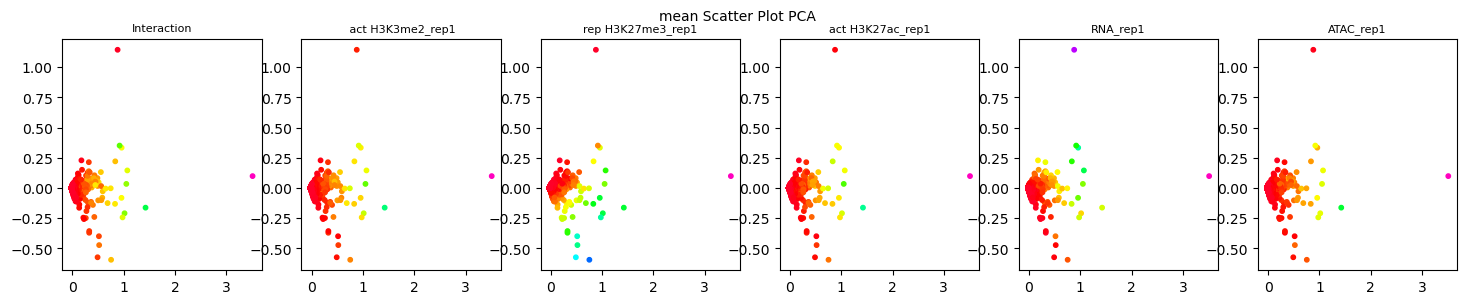

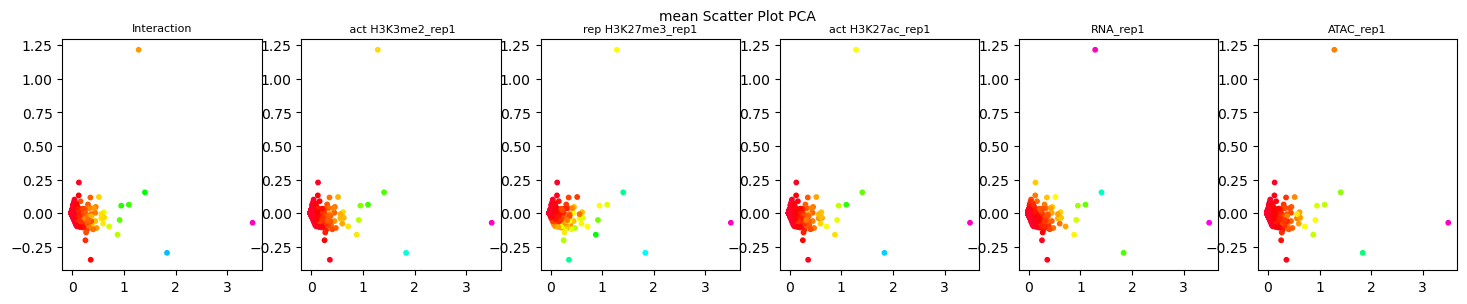

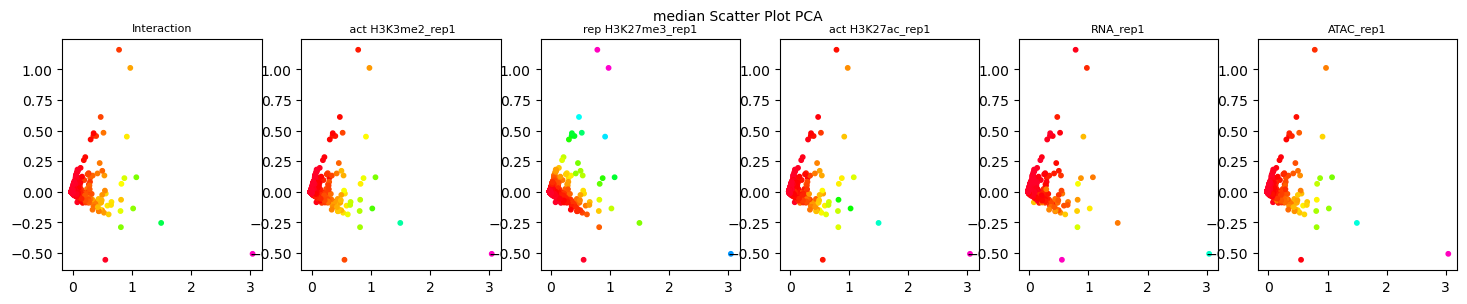

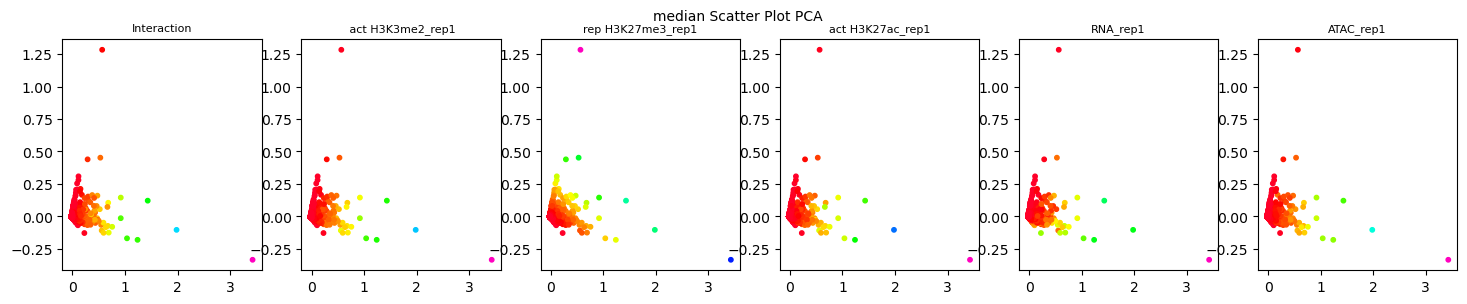

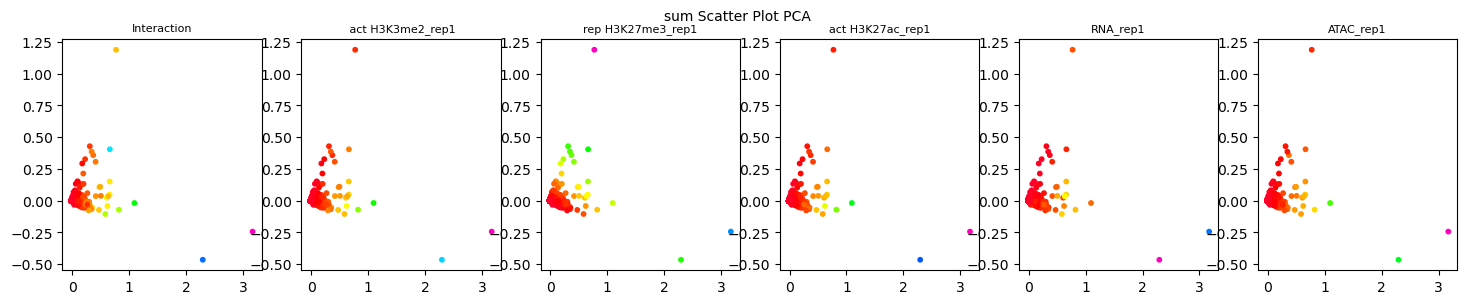

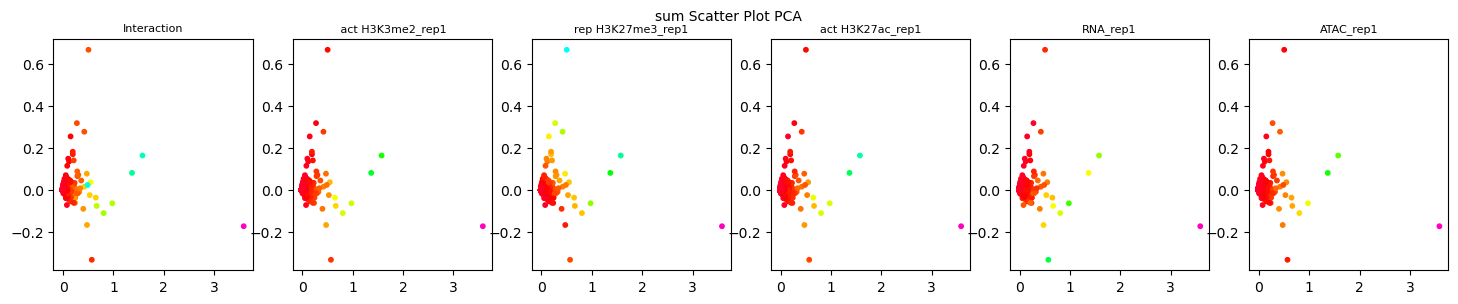

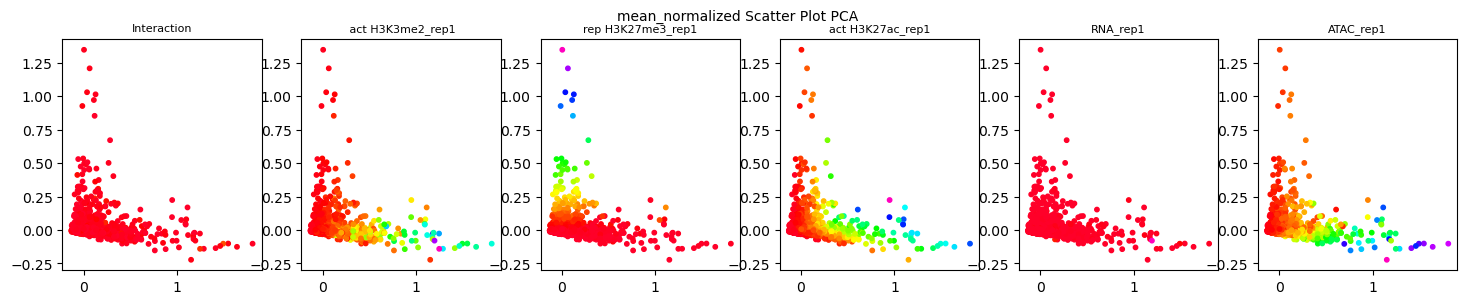

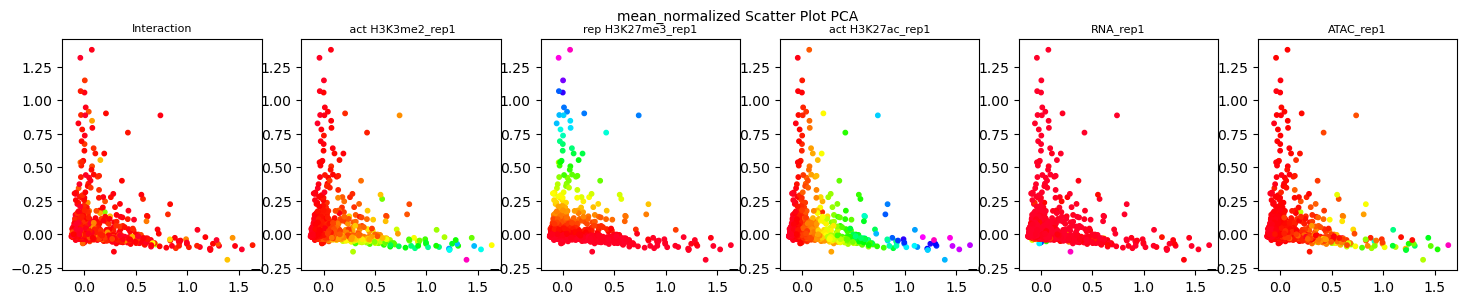

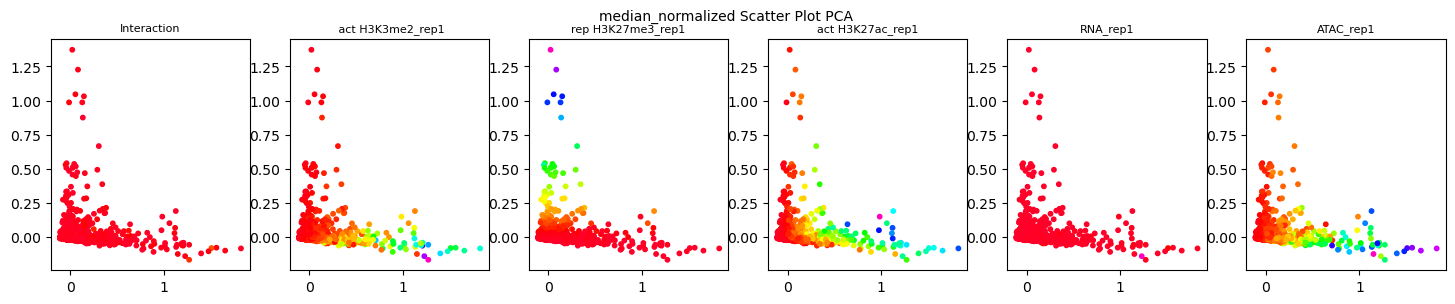

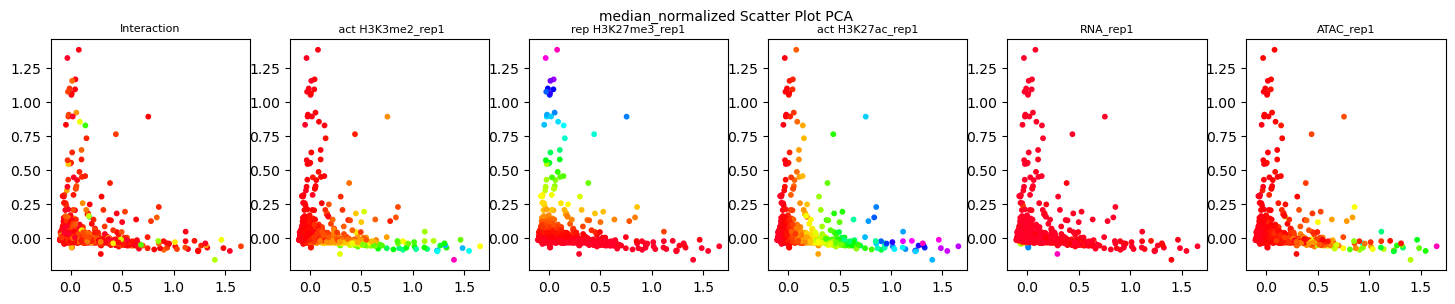

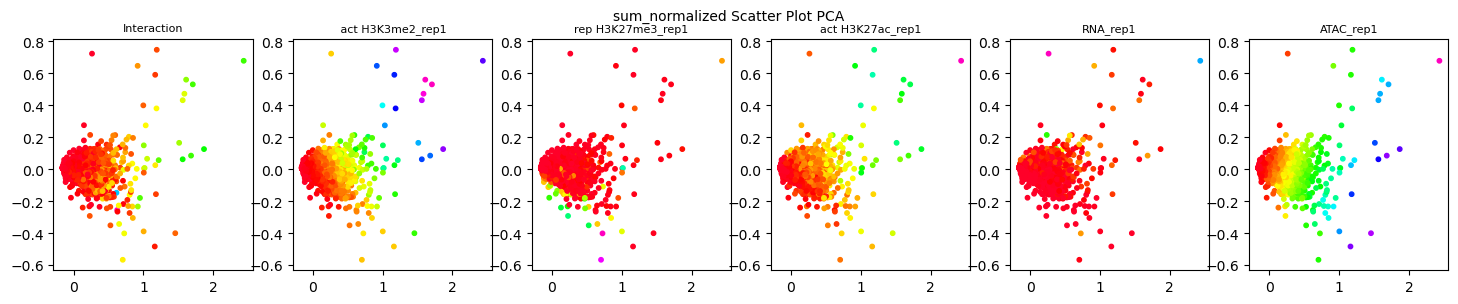

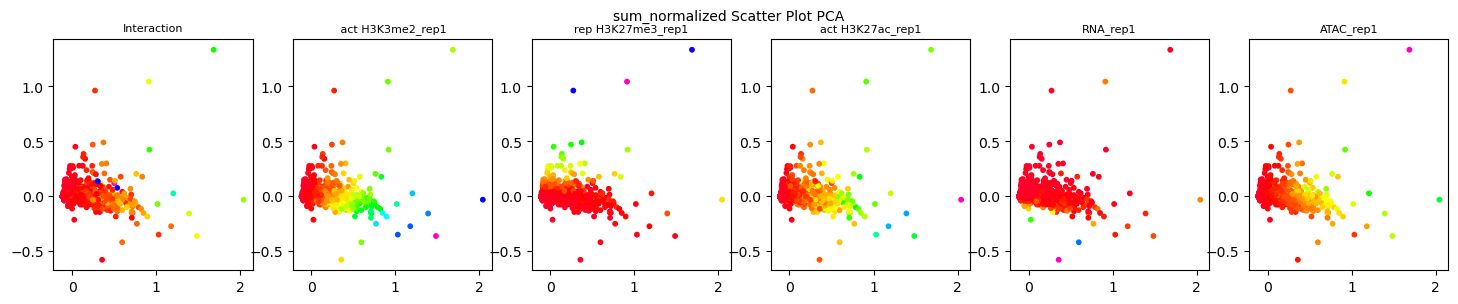

In [26]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotPCA(different_communities_Pinna_E_12_5[i], title)
    plotPCA(different_communities_Pinna_E_14_5[i], title)


In [16]:
def plotUMAP(matrix, type_of_matrix):
    embedding = reducer.fit_transform(matrix)
    title = "Scatter Plot PCA"
    # list_of_titles = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
    list_of_titles = ["Interaction", " act H3K3me2_rep1",  "rep H3K27me3_rep1", "act H3K27ac_rep1","RNA_rep1",  "ATAC_rep1"]
    # list_of_colorings = community_matrix_median.T.tolist()

    list_of_colorings = matrix.T[[0,1,3,5,7,10]].tolist()

    plotEmbedding([embedding[:, 0], embedding[:, 1]], list_of_titles, list_of_colorings, type_of_matrix + " " + title)

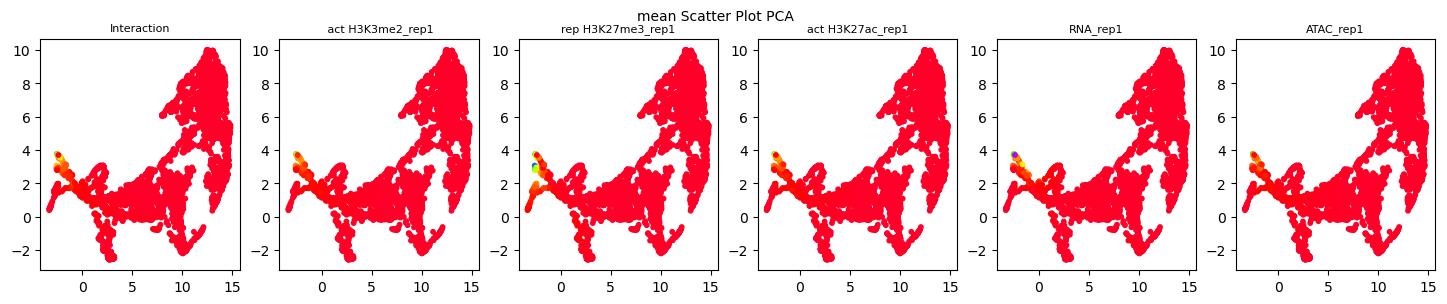

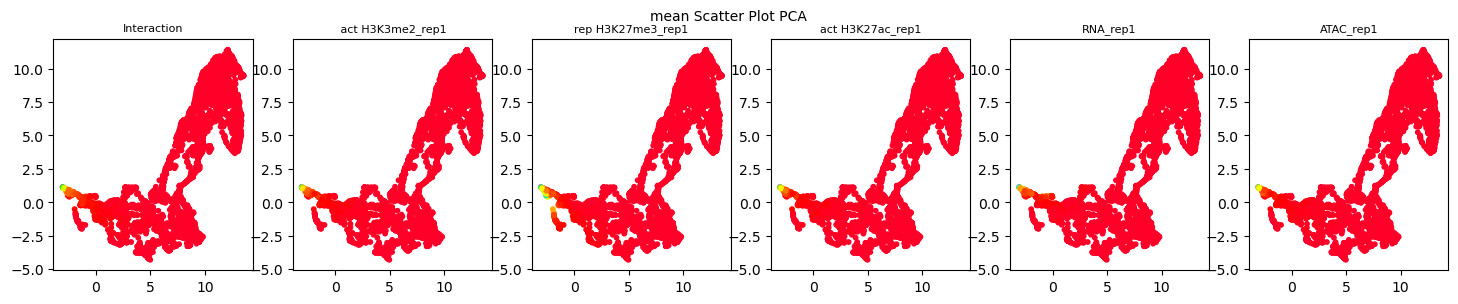

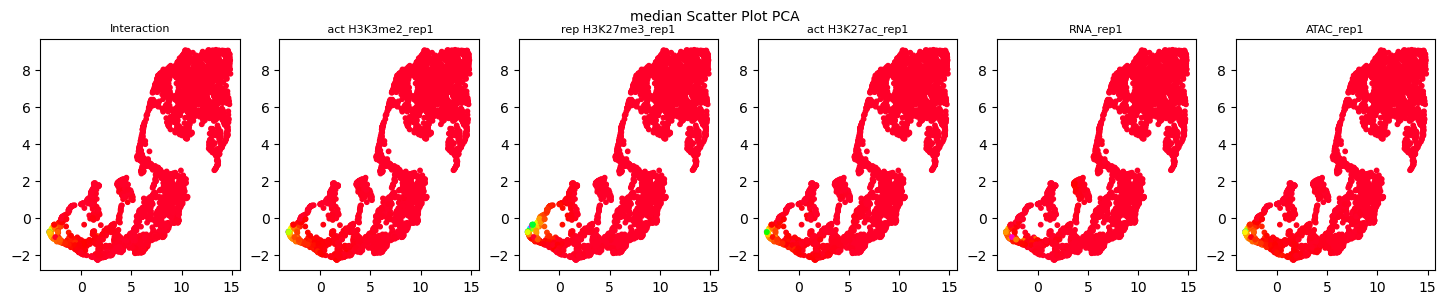

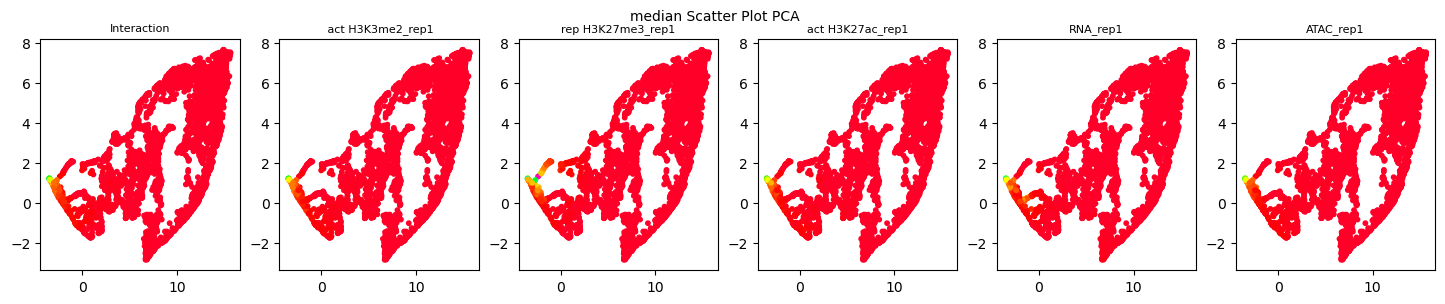

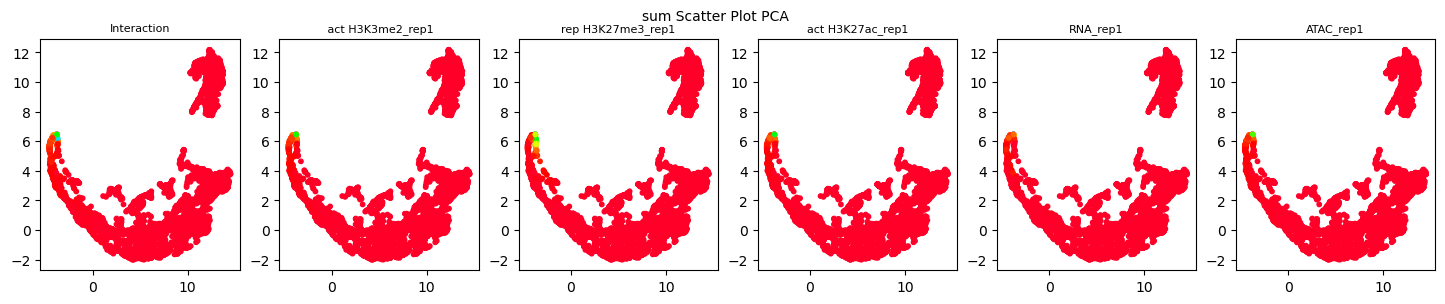

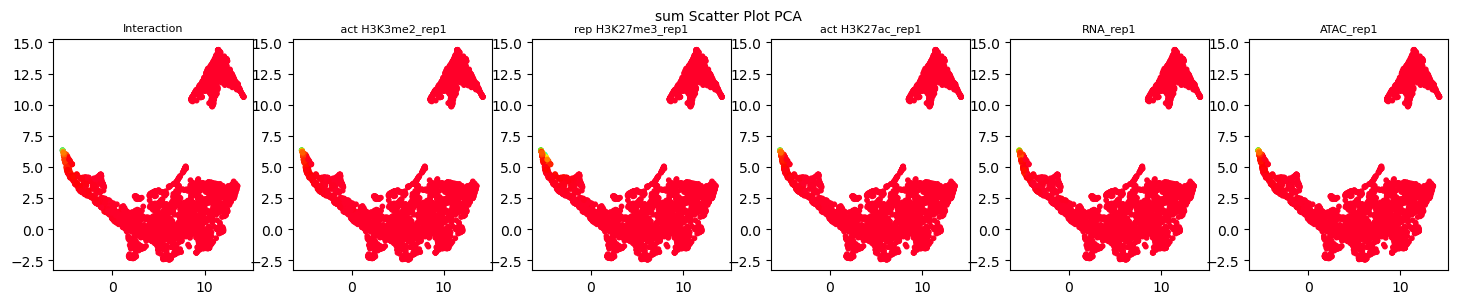

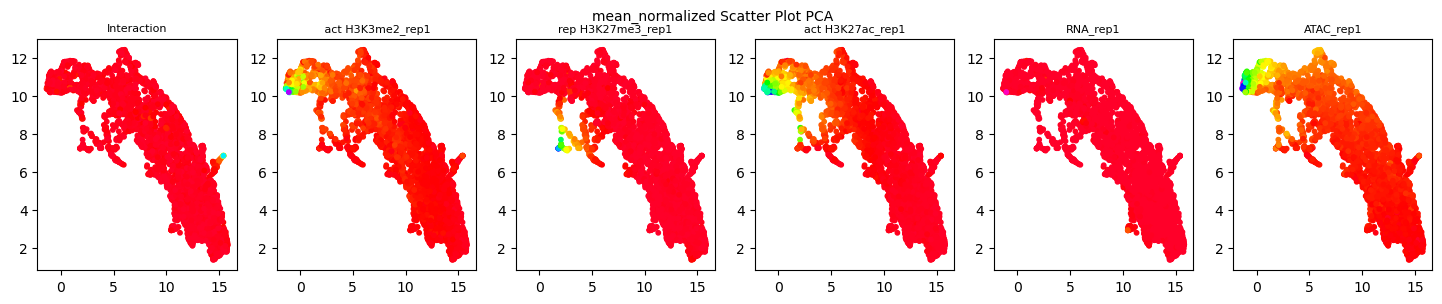

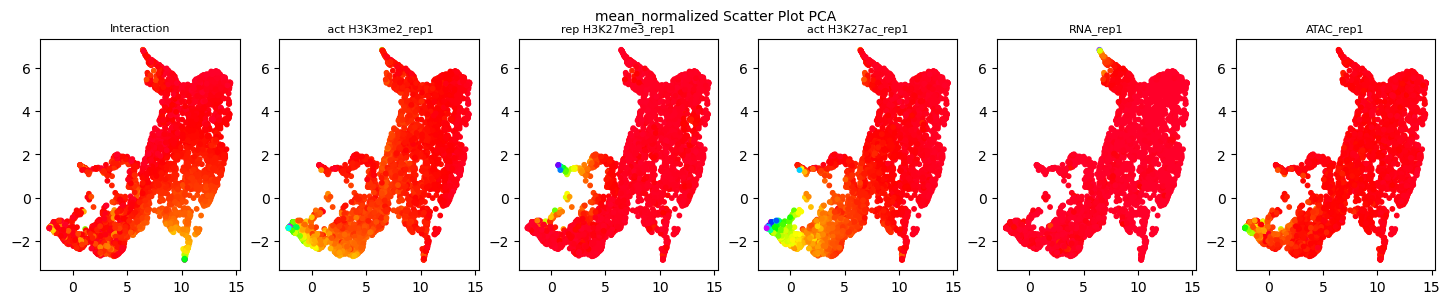

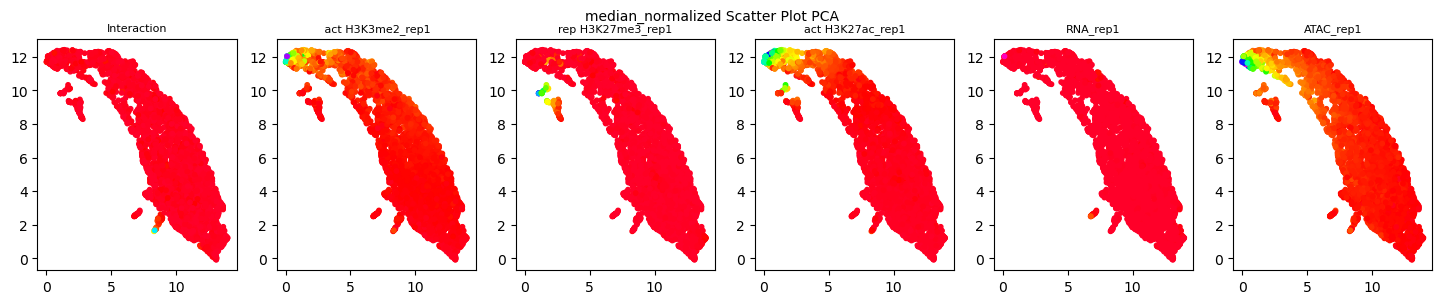

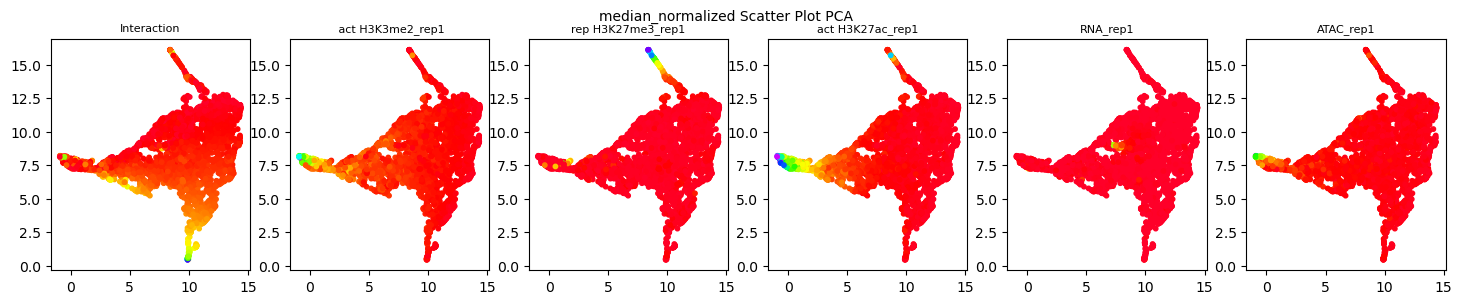

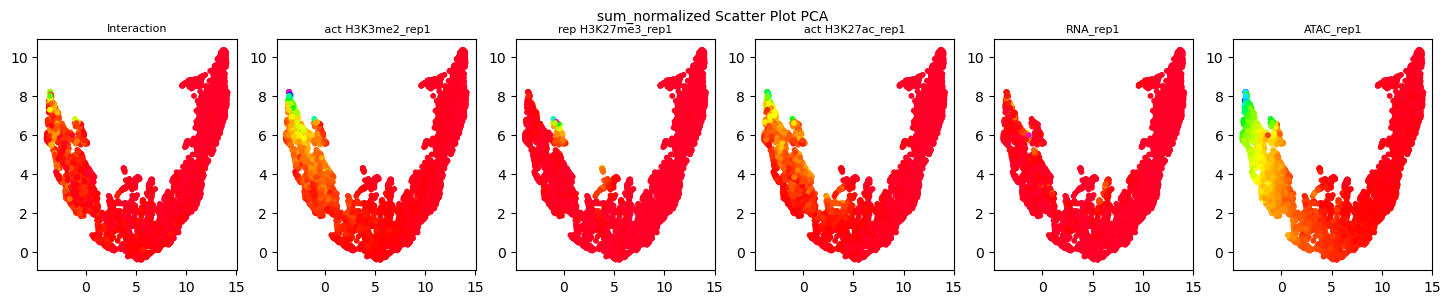

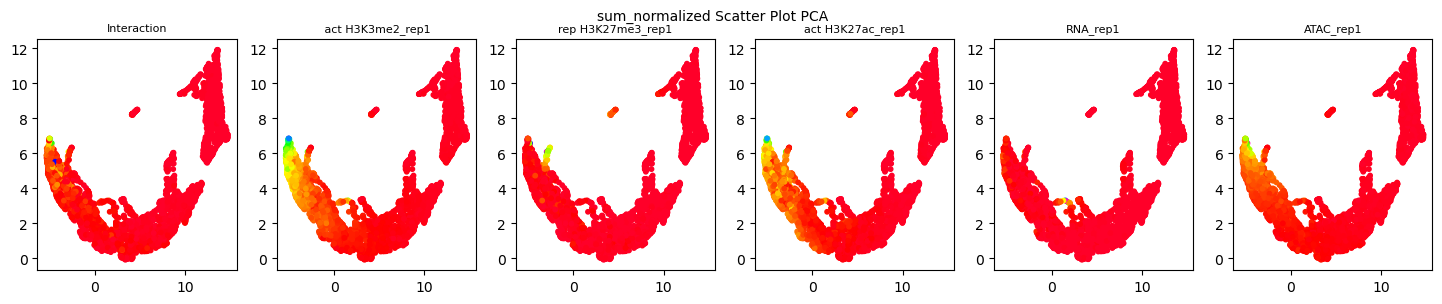

In [27]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotUMAP(different_communities_Pinna_E_12_5[i], title)
    plotUMAP(different_communities_Pinna_E_14_5[i], title)


In [33]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotPCA(different_communities_Pinna_E_14_5[i], title)

In [201]:
plotPCA(different_communities_Pinna_E_14_5[0] - different_communities_Pinna_E_12_5[0], title)

ValueError: operands could not be broadcast together with shapes (2349,13) (2457,13) 

In [37]:
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors()



In [17]:
def plotEmbedding(list_of_embeddings, list_of_subtitles, list_of_colorings, title_of_plot, fontsize=8):
    fig, axs = plt.subplots(1, len(list_of_subtitles), figsize=(3 * len(list_of_subtitles), 3))

    for i, (title, coloring) in enumerate(zip(list_of_subtitles, list_of_colorings)):
        # Plot the first version
        axs[i].scatter(list_of_embeddings[0], list_of_embeddings[1], c=coloring, cmap='gist_rainbow', s=10)  # Change the value of s to adjust the dot size
        axs[i].set_title(title, fontsize=fontsize)

    fig.suptitle(title_of_plot, fontsize=fontsize+2)
    plt.show()

In [27]:
import matplotlib.pyplot as plt

In [328]:
len(different_communities_Pinna_E_12_5[-1])

469

In [325]:
plt.figure(figsize=(15, 8))
plot_matrix = different_communities_Pinna_E_14_5[-1] - different_communities_Pinna_E_12_5[-1]
sorted_indices = np.argsort(plot_matrix[:, 1])
sorted_matrix = plot_matrix[sorted_indices]
plt.imshow(sorted_matrix, cmap='RdBu_r', interpolation='nearest', aspect='auto')
plt.title('Community Matrix')
plt.xlabel('Matrix Columns')
plt.ylabel('Community ID')
plt.colorbar()

# Add ticks per column with text in 45-degree angle
ticks = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
plt.xticks(range(len(ticks)), ticks, rotation=90, fontsize=8)



ValueError: operands could not be broadcast together with shapes (1962,13) (469,13) 

<Figure size 1500x800 with 0 Axes>

In [ ]:
plt.show()

In [ ]:
elements_per_community

array([ 55., 228., 161., ...,   1.,   1.,   1.])

In [ ]:
np.mean(matrix[community_id, :].tocsr().data)

0.018751868987494782

In [ ]:
matrix[community_id, :].tocsr().data

array([0.00911416, 0.02037817, 0.02676329])

In [ ]:
bw.chroms()

{'chr1': 195471971,
 'chr10': 130694993,
 'chr11': 122082543,
 'chr12': 120129022,
 'chr13': 120421639,
 'chr14': 124902244,
 'chr15': 104043685,
 'chr16': 98207768,
 'chr17': 94987271,
 'chr18': 90702639,
 'chr19': 61431566,
 'chr1_GL456210_random': 169725,
 'chr1_GL456211_random': 241735,
 'chr1_GL456212_random': 153618,
 'chr1_GL456213_random': 39340,
 'chr1_GL456221_random': 206961,
 'chr2': 182113224,
 'chr3': 160039680,
 'chr4': 156508116,
 'chr4_GL456216_random': 66673,
 'chr4_GL456350_random': 227966,
 'chr4_JH584292_random': 14945,
 'chr4_JH584293_random': 207968,
 'chr4_JH584294_random': 191905,
 'chr4_JH584295_random': 1976,
 'chr5': 151834684,
 'chr5_GL456354_random': 195993,
 'chr5_JH584296_random': 199368,
 'chr5_JH584297_random': 205776,
 'chr5_JH584298_random': 184189,
 'chr5_JH584299_random': 953012,
 'chr6': 149736546,
 'chr7': 145441459,
 'chr7_GL456219_random': 175968,
 'chr8': 129401213,
 'chr9': 124595110,
 'chrM': 16299,
 'chrUn_GL456239': 40056,
 'chrUn_GL456359

## Is the bait still in the same community between conditions?

In [ ]:
partition_Pinna_E12_5
partition_Pinna_E14_5

In [30]:
# bait view, community view 

partition_Pinna_E12_5

{1: 0,
 26258: 0,
 52468: 0,
 2: 1,
 26130: 1,
 26147: 1,
 26149: 1,
 26150: 1,
 26154: 1,
 3: 2,
 25869: 2,
 26038: 2,
 4: 3,
 25784: 3,
 6: 4,
 26463: 4,
 26464: 4,
 26553: 4,
 26574: 4,
 9: 5,
 26328: 5,
 26336: 5,
 26338: 5,
 26575: 5,
 27383: 5,
 27494: 5,
 27544: 5,
 10: 5,
 11: 5,
 26315: 5,
 26317: 5,
 26593: 5,
 26594: 5,
 26595: 5,
 26596: 5,
 26597: 5,
 26606: 5,
 26616: 5,
 26633: 5,
 26659: 5,
 26660: 5,
 26661: 5,
 26662: 5,
 26687: 5,
 26699: 5,
 26703: 5,
 26709: 5,
 26710: 5,
 26712: 5,
 26713: 5,
 26714: 5,
 26715: 5,
 12: 5,
 27589: 5,
 13: 5,
 27604: 5,
 14: 5,
 15: 5,
 26587: 5,
 27568: 5,
 27580: 5,
 27581: 5,
 27583: 5,
 27591: 5,
 27597: 5,
 27598: 5,
 27611: 5,
 18: 5,
 26578: 5,
 27467: 5,
 27482: 5,
 27483: 5,
 27487: 5,
 27490: 5,
 27492: 5,
 27495: 5,
 27497: 5,
 477522: 5,
 20: 6,
 27647: 6,
 28611: 6,
 21: 7,
 27850: 7,
 23: 8,
 28143: 8,
 28173: 8,
 28197: 8,
 28327: 8,
 28384: 8,
 25: 9,
 28654: 9,
 26: 10,
 29340: 10,
 29841: 10,
 27: 2,
 29789: 2,
 29

In [41]:
len(bait_list_Pinna_E14_5)

25111

In [57]:
bait_list_Pinna_E14_5

[Name    Lypla1_1
 Name: 0, dtype: object,
 Name    Tcea1_1
 Name: 1, dtype: object,
 Name    Atp6v1h_1
 Name: 2, dtype: object,
 Name    Oprk1_1
 Name: 3, dtype: object,
 Name    Rb1cc1_1
 Name: 4, dtype: object,
 Name    Alkal1_1
 Name: 5, dtype: object,
 Name    St18_3
 Name: 6, dtype: object,
 Name    St18_2
 Name: 7, dtype: object,
 Name    St18_1
 Name: 8, dtype: object,
 Name    Pcmtd1_1
 Name: 9, dtype: object,
 Name    Pcmtd1_2
 Name: 10, dtype: object,
 Name    Rrs1_1
 Name: 11, dtype: object,
 Name    Adhfe1_1
 Name: 12, dtype: object,
 Name    3110035E14Rik_1
 Name: 13, dtype: object,
 Name    3110035E14Rik_2
 Name: 14, dtype: object,
 Name    Sgk3_1
 Name: 15, dtype: object,
 Name    Sgk3_2
 Name: 16, dtype: object,
 Name    Mcmdc2_1
 Name: 17, dtype: object,
 Name    Cspp1_1
 Name: 18, dtype: object,
 Name    Cspp1_2
 Name: 19, dtype: object,
 Name    Prex2_1
 Name: 20, dtype: object,
 Name    A830018L16Rik_1
 Name: 21, dtype: object,
 Name    Sulf1_2
 Name: 22, dtype: ob

In [104]:
graph_intersection = nx.intersection(G_Pinna_E12_5, G_Pinna_E14_5)

In [84]:
graph_intersection.edges

EdgeView([(393216, 22915), (2, 26147), (2, 26150), (393217, 23228), (393217, 22915), (4, 25784), (393220, 23228), (393220, 22915), (6, 26464), (393221, 22917), (393221, 23228), (393221, 22915), (11, 26597), (11, 26715), (11, 26662), (11, 26661), (11, 26660), (11, 26713), (11, 26709), (11, 26594), (11, 26593), (11, 26710), (11, 26595), (11, 26659), (11, 26596), (15, 27591), (15, 27598), (15, 27580), (15, 27581), (393226, 23230), (393226, 22915), (18, 27487), (18, 27494), (18, 27495), (18, 27497), (393228, 22915), (393228, 23227), (393229, 22915), (393229, 23227), (393233, 23233), (25, 28654), (26, 29340), (27, 29837), (27, 29838), (27, 29839), (28, 30058), (393243, 23233), (30, 30205), (30, 30207), (31, 30080), (31, 30077), (31, 30074), (31, 30067), (32, 30067), (34, 30946), (34, 31118), (34, 31134), (34, 30947), (34, 31138), (34, 31135), (34, 31136), (34, 31051), (34, 31120), (34, 31114), (34, 31059), (34, 31137), (34, 30945), (35, 30945), (35, 31136), (35, 31137), (35, 31059), (35, 31

In [85]:
R = G_Pinna_E12_5.copy()
R.remove_nodes_from(n for n in G_Pinna_E12_5 if n not in G_Pinna_E14_5)
R.remove_edges_from(e for e in G_Pinna_E12_5.edges if e not in G_Pinna_E14_5.edges)

In [88]:
deleted_nodes = G_Pinna_E12_5.copy()
deleted_nodes.remove_nodes_from(n for n in G_Pinna_E12_5 if n in G_Pinna_E14_5)
deleted_nodes.remove_edges_from(e for e in G_Pinna_E12_5.edges if e in G_Pinna_E14_5.edges)

In [89]:
deleted_nodes.edges

EdgeView([(3, 26038), (20, 27647), (30209, 13497), (37, 455155), (170, 43819), (43819, 968), (171, 36667), (171, 43892), (36667, 172), (36667, 969), (43892, 172), (43892, 969), (174, 43712), (174, 43727), (174, 43943), (174, 44090), (197, 45102), (235, 49058), (235, 49060), (248, 49154), (49154, 1037), (287, 51310), (51310, 1072), (338, 53226), (346, 53628), (346, 53631), (54733, 1113), (426, 63514), (426, 63664), (426, 63769), (426, 63789), (63514, 427), (63514, 1169), (63664, 427), (63664, 1169), (63769, 427), (63769, 1169), (63789, 427), (63789, 1169), (430, 64300), (66243, 1191), (66243, 1192), (439, 66491), (470, 67827), (470, 84928), (505, 68574), (505, 68590), (520, 68877), (520, 68880), (68877, 521), (68877, 1260), (68880, 521), (534, 69263), (614, 77422), (620, 77794), (620, 78190), (621, 77784), (621, 77850), (621, 78159), (621, 125408), (77784, 1372), (77850, 1372), (78159, 1372), (125408, 1372), (623, 78543), (636, 78931), (636, 79123), (83835, 1491), (83848, 733), (749, 85

In [91]:
nx.write_graphml(R, ROOT_PATH + "Pinna_E12_5_E_14_5_intersection.graphml")

In [92]:
nx.write_graphml(deleted_nodes, ROOT_PATH + "Pinna_E12_5_E_14_5_non_intersection.graphml")

In [1]:
len(matching_community_list)

NameError: name 'matching_community_list' is not defined

In [93]:
nx.graph_edit_distance(G_Pinna_E12_5, G_Pinna_E14_5)

KeyboardInterrupt: 

In [105]:
communities_E12_5 = nx.community.louvain_communities(G_Pinna_E12_5, seed=42)

In [106]:
communities_E14_5 = nx.community.louvain_communities(G_Pinna_E14_5, seed=42)

In [121]:
intersection_communities_nodes = []
intersection_communities_jaccard = np.zeros((len(communities_E12_5), len(communities_E14_5)))
intersection_communities_bait_jaccard = np.zeros((len(communities_E12_5), len(communities_E14_5)))
for i in range(len(communities_E12_5)):
    intersection_communities_nodes.append([])
    for j in range(len(communities_E14_5)):
        intersection = communities_E12_5[i].intersection(communities_E14_5[j])

        if len(intersection) > 0:
            intersection_communities_nodes[i].append(intersection)
            intersection_communities_jaccard[i, j] = len(intersection) / len(communities_E12_5[i].union(communities_E14_5[j]))
            specific_value = sample_matrix_Pinna_E12_5.shape[0]
            bait_intersection = {x for x in intersection if x <= specific_value}
            bait_E12_5 = {x for x in communities_E12_5[i] if x <= specific_value}
            bait_E14_5 = {x for x in communities_E14_5[j] if x <= specific_value}
            intersection_communities_bait_jaccard[i, j] = len(bait_intersection) / len(bait_E12_5.union(bait_E14_5))



In [108]:
intersection_communities_bait_jaccard[1268, 1252]

0.7692307692307693

In [109]:
intersection_communities_jaccard[1268, 1252]

0.4114583333333333

In [122]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values = np.sort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices = np.argsort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)


Top 10 values per row:
[[0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[ 127 3599 1208 1206 1205]
 [ 127 3599 1208 1206 1205]
 [ 127 3599 1208 1206 1205]
 ...
 [3597 3599 1194 1206 1205]
 [3598 1181 1207 1206 1205]
 [3599 1236 1206 1205 1204]]


In [123]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values_communities = np.sort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices_communities = np.argsort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)

Top 10 values per row:
[[0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[ 127 3599 1208 1206 1205]
 [ 127 3599 1208 1206 1205]
 [ 127 3599 1208 1206 1205]
 ...
 [3597 3599 1194 1206 1205]
 [3598 1181 1207 1206 1205]
 [3599 1236 1206 1205 1204]]


In [130]:
top_10_indices[3000]

array([2876, 3599, 1194, 1205, 1204])

In [127]:
top_10_indices_communities[3000]

array([2876, 3599, 1194, 1205, 1204])

In [128]:
top_10_values_communities[3000]

array([0.85714286, 0.        , 0.        , 0.        , 0.        ])

In [129]:
top_10_values[3000]

array([1., 0., 0., 0., 0.])

In [124]:
intersection_communities_nodes[1268]

[{8146, 8147, 642455, 642467, 642579, 642580},
 {641455},
 {8133,
  8137,
  8138,
  8139,
  8140,
  8142,
  8143,
  8144,
  8145,
  8761,
  8765,
  8766,
  8767,
  8768,
  8769,
  8771,
  8773,
  8774,
  8775,
  8776,
  641958,
  641960,
  641961,
  642001,
  642002,
  642003,
  642013,
  642074,
  642075,
  642076,
  642077,
  642078,
  642079,
  642080,
  642081,
  642082,
  642083,
  642084,
  642085,
  642086,
  642087,
  642088,
  642089,
  642096,
  642198,
  642199,
  642309,
  642310,
  642351,
  642352,
  642353,
  642355,
  642356,
  642358,
  642359,
  642360,
  642361,
  642411,
  642413,
  642426,
  642436,
  642437,
  642549,
  642551,
  642552,
  642554,
  642555,
  642559,
  642560,
  642562,
  642602,
  642606,
  642646,
  642649,
  642650,
  642651,
  642653,
  642671,
  642672}]

After the jaccard similarity sorting:
- Which baits are equal between clusters?
- Which baits changed the cluster?
- Which baits are exclusive in one sample? For example jaccard similarity of Hoxa2 cluster is 0.76 to the clostest one, 0.03 to the next, and to all other 0. Where are the missing 0.2? Ideas: Baits are exclusive in sample 1 xor sample 2.

- For equal: 
  - How did the histone / RNA changed between the conditions? 
    - per both sides of the interaction get the histone / RNA / ATAC data, with replicates for DESeq2 table
  - How did the interaction strength changed? (Binary contact number change / summed value change / mean change) per community

- Baits changed cluster:
  - How did the histone / RNA changed between the conditions? 
  - How did it changed at those contacts that were lost / gained? Identifiy the contacts responsible for the loss / gain within the community. Get for both ends of a gained / lost contact from both samples the Histone / RNA / ATAC data for Deseq2 table

- Exclusive in one sample:
  - How did the histone / RNA changed between the conditions at the locations of baits / OE? 

Can we identifiy patterns? 
- 


In [115]:
communities_E12_5[1268].intersection(communities_E14_5[1246])

{8146, 8147, 642455, 642467, 642579, 642580}

In [ ]:
# Tax1bp1_2

In [111]:
# Sort the values per highest row numbers
sorted_values = np.sort(top_10_values, axis=1)[:, ::-1]

# Keep the indices of the rows
sorted_indices = np.argsort(top_10_values, axis=1)[:, ::-1]

# Print the sorted values and indices
print("Sorted values per highest row numbers:")
print(sorted_values)
print("Indices of the rows:")
print(sorted_indices)


Sorted values per highest row numbers:
[[0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]]
Indices of the rows:
[[0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]
 ...
 [0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]]


In [67]:
top_10_values[1295, :]

array([0.76923077, 0.04081633, 0.        , 0.        , 0.        ])

In [68]:
top_10_indices[1295, :]

array([1293, 1401, 3692, 1239, 1237])

In [62]:
top_10_indices[3692, :]

array([3509, 3508, 3692, 1224, 1235])

In [59]:
top_10_values.shape

(3884, 5)

In [39]:
print(communities_E12_5[1295].intersection(communities_E14_5[1293]))
print(len(communities_E12_5[1295].intersection(communities_E14_5[1293])))

print(len(communities_E12_5[1295]))
print(len(communities_E14_5[1293]))


{642560, 642562, 642074, 642075, 642076, 642077, 642078, 642079, 642080, 642081, 642082, 642083, 642084, 642085, 642086, 642087, 642088, 642089, 642602, 642606, 642096, 8761, 8765, 8766, 8767, 8768, 8769, 8771, 8773, 8774, 8775, 8776, 642646, 642649, 642650, 642651, 642653, 642671, 642672, 642198, 642199, 642309, 642310, 642351, 642352, 642353, 642355, 642356, 642358, 642359, 642360, 642361, 642411, 642413, 642426, 642436, 642437, 641958, 641960, 641961, 8133, 8137, 8138, 8139, 8140, 8142, 8143, 8144, 642001, 642002, 642003, 8145, 642013, 642549, 642551, 642552, 642554, 642555, 642559}
79
155
116


In [37]:
for i in range(len(communities_E12_5)):
    if 8767 in communities_E12_5[i]:
        print(i)
        break
for i in range(len(communities_E14_5)):
    if 8767 in communities_E14_5[i]:
        print(i)
        break

1295
1293


In [36]:
bait_list_Pinna_E12_5[8767]

Name    Hoxa2_1
Name: 8767, dtype: object

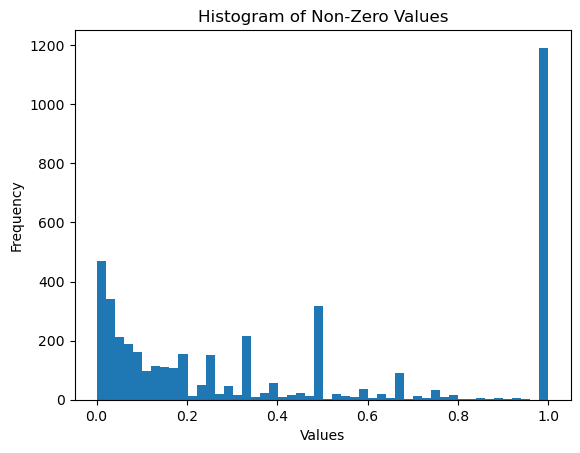

In [137]:
import numpy as np
import matplotlib.pyplot as plt

matrix = top_10_values
# Assuming your 2D matrix is named 'matrix'
non_zero_values = matrix[matrix != 0]

# Plot the histogram
plt.hist(non_zero_values, bins=50)
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.title('Histogram of Non-Zero Values')
plt.show()


In [133]:
non_zero_values

array([0.02380952, 0.02380952, 0.02380952, ..., 1.        , 1.        ,
       1.        ])

In [119]:
import multiprocessing
distance_matrix = np.full((len(communities_E12_5), len(communities_E14_5)), -1)
subgraphs_E12_5 = []
subgraphs_E14_5 = []

def compute_distance(i, j):
    subgraph_E12_5 = G_Pinna_E12_5.subgraph(communities_E12_5[i])
    subgraph_E14_5 = G_Pinna_E14_5.subgraph(communities_E14_5[j])
    if nx.is_isomorphic(subgraph_E12_5, subgraph_E14_5):
        distance_matrix[i, j] = 0
    else:
        distance_matrix[i, j] = nx.optimize_graph_edit_distance(subgraph_E12_5, subgraph_E14_5)

pool = multiprocessing.Pool()
for i in range(len(communities_E12_5)):
    for j in range(len(communities_E14_5)):
        pool.apply_async(compute_distance, args=(i, j))

pool.close()
pool.join()


KeyboardInterrupt: 

: 

In [118]:
distance_matrix

array([[-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       ...,
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1]])

In [102]:
max(partition_Pinna_E12_5.values())

3887

In [103]:
len(community_E14_5)

3693

In [104]:
max(partition_Pinna_E14_5.values())

3691